# 21. 보고서용 KAMP 그림 — 결합 사양 추천을 현장에서 읽는 방법
A. 날짜별 검사 수량: 결합 등급 A(상위 c_d, c_d = 그날 불량 수, 3/27은 추정 6개), B(c_d~5c_d), 비율 예산 10%와 비교
B. 하루 생산 순서 위의 결합 점수와 추천 위치(예시: 불량이 가장 많은 3/26). 추천이 특정 구간에 몰리는지 본다.
C. 추천 타점의 조건 분포(전류·통전시간)를 나머지와 비교한다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import br
from br import spec as S, plot as P
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
K = pd.read_csv(br.RES / "final_kamp_recommendations_combined.csv")
_, kday, kcnt, _, kblk = S.load_kamp()
c_use = kcnt.copy(); c_use["2020-03-27"] = 6
ok = ~kblk
tier = np.full(len(K), "C", dtype=object); tier[kblk] = "품질확인"
for d in np.unique(kday):
    m = ok & (kday == d); ix = np.flatnonzero(m); order = ix[np.argsort(-K["결합점수"].values[m], kind="stable")]
    c = int(c_use[d]); tier[order[:5 * c]] = "B"; tier[order[:c]] = "A"
K["결합 등급"] = tier
K.to_csv(br.RES / "final_kamp_recommendations_combined.csv", index=False, encoding="utf-8-sig")
tab = pd.crosstab(K.date, K["결합 등급"])[["A", "B", "C", "품질확인"]]
tab["10% 예산"] = K.groupby("date")["추천_10%"].sum()
tab["실제 불량"] = kcnt.reindex(tab.index)
display(tab)

결합 등급,A,B,C,품질확인,10% 예산,실제 불량
date,,,,,,
2020-03-24,4,16,1180,0,120,4.0
2020-03-25,8,32,1021,291,107,8.0
2020-03-26,7,28,965,0,100,7.0
2020-03-27,6,24,1327,291,136,NaN
2020-03-30,4,16,1450,0,147,4.0
2020-03-31,5,20,1484,291,151,5.0
2020-04-02,4,16,1980,0,200,4.0
2020-04-03,4,16,489,291,51,4.0
2020-04-07,3,12,654,0,67,3.0


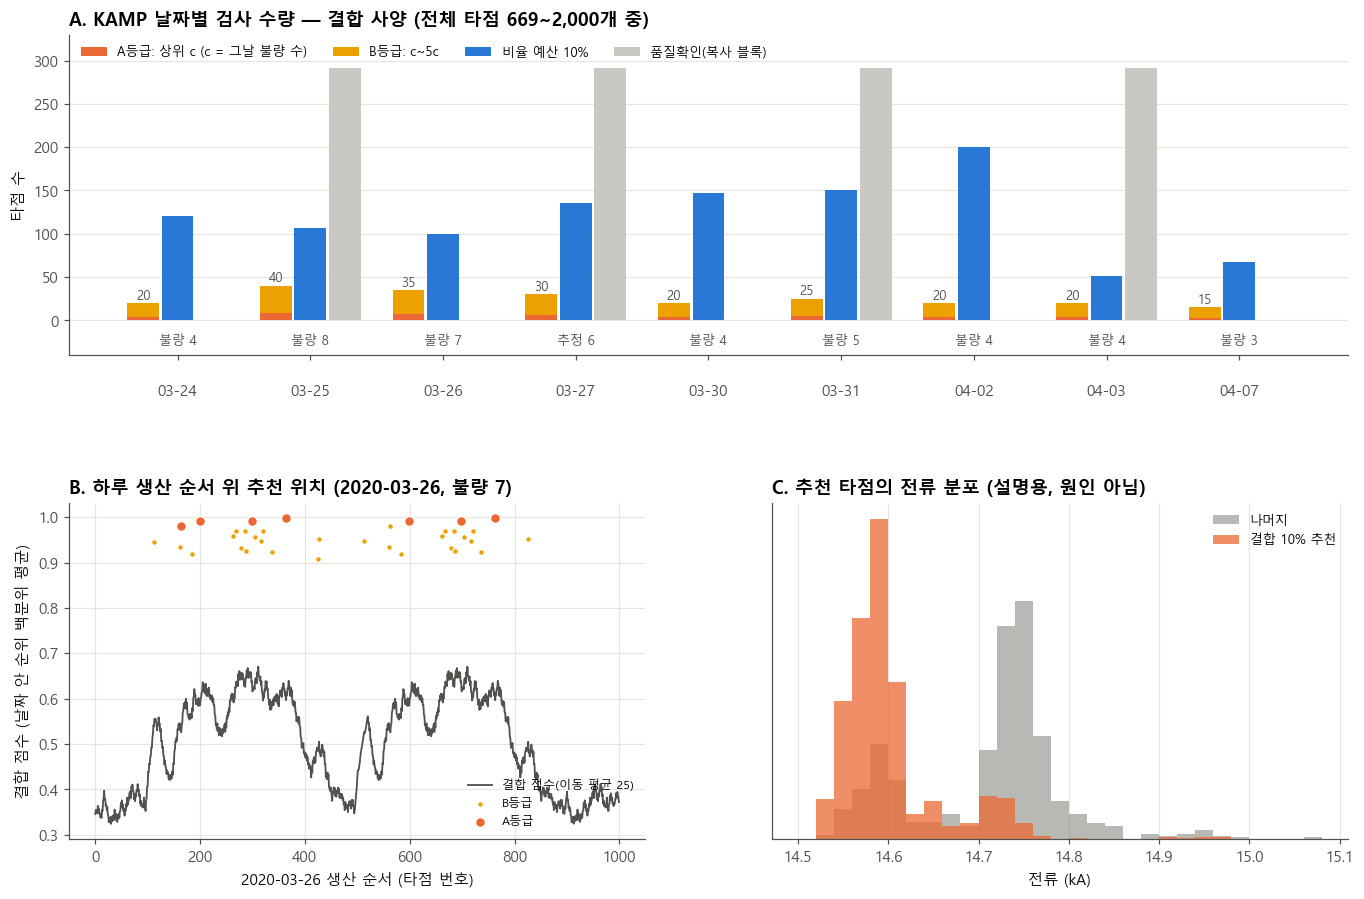

In [2]:
fig = plt.figure(figsize=(15, 9.5)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], hspace=.45, wspace=.22)
ax = fig.add_subplot(gs[0, :])
x = np.arange(len(tab)); w = .26
ax.bar(x - w, tab["A"], w * .92, color=P.PAL[1], label="A등급: 상위 c (c = 그날 불량 수)")
ax.bar(x - w, tab["B"], w * .92, bottom=tab["A"], color=P.PAL[3], label="B등급: c~5c")
ax.bar(x, tab["10% 예산"], w * .92, color=P.PAL[0], label="비율 예산 10%")
ax.bar(x + w, tab["품질확인"], w * .92, color="#c9c8c2", label="품질확인(복사 블록)")
for i, (d, r) in enumerate(tab.iterrows()):
    a = "추정 6" if np.isnan(r["실제 불량"]) else f"불량 {int(r['실제 불량'])}"
    ax.text(i - w, r["A"] + r["B"] + 4, f"{int(r['A'] + r['B'])}", ha="center", fontsize=8.5, color=P.INK2)
    ax.text(i, -28, a, ha="center", fontsize=8.5, color=P.INK2)
ax.set_xticks(x); ax.set_xticklabels([f"\n{d[5:]}" for d in tab.index]); ax.set_ylabel("타점 수"); ax.grid(axis="x", visible=False)
ax.set_ylim(-40, 330); ax.legend(fontsize=8.5, ncol=4, loc="upper left")
ax.set_title("A. KAMP 날짜별 검사 수량 — 결합 사양 (전체 타점 669~2,000개 중)", loc="left", fontweight="bold")
ax = fig.add_subplot(gs[1, 0])
d0 = "2020-03-26"; m = (K.date == d0).values
seq = np.arange(m.sum()); s = K.loc[m, "결합점수"].values; t = K.loc[m, "결합 등급"].values
ax.plot(seq, pd.Series(s).rolling(25, center=True, min_periods=5).mean(), color=P.INK2, lw=1.2, label="결합 점수(이동 평균 25)")
for g, col, sz in [("B", P.PAL[3], 14), ("A", P.PAL[1], 40)]:
    ax.scatter(seq[t == g], s[t == g], s=sz, color=col, edgecolor="white", linewidth=.8, zorder=3, label=f"{g}등급")
ax.set_xlabel(f"{d0} 생산 순서 (타점 번호)"); ax.set_ylabel("결합 점수 (날짜 안 순위 백분위 평균)")
ax.set_title(f"B. 하루 생산 순서 위 추천 위치 ({d0}, 불량 7)", loc="left", fontweight="bold"); ax.legend(fontsize=8, loc="lower right")
ax = fig.add_subplot(gs[1, 1])
top = (K["추천_10%"].values) & ok; rest = ok & ~top
cur = K["weld current(kA)"].values
bins = np.round(np.arange(14.50, 15.10, 0.02), 2)
ax.hist(cur[rest], bins=bins, density=True, color=P.GRAY, alpha=.6, label="나머지")
ax.hist(cur[top], bins=bins, density=True, color=P.PAL[1], alpha=.75, label="결합 10% 추천")
ax.set_xlabel("전류 (kA)"); ax.set_yticks([]); ax.legend(fontsize=8.5)
ax.set_title("C. 추천 타점의 전류 분포 (설명용, 원인 아님)", loc="left", fontweight="bold")
P.save(fig, "19_kamp_report"); plt.show()